In [2]:
from dotenv import load_dotenv
load_dotenv()  # loads ALPHA_GENOME_API_KEY from .env

from alphagenome import colab_utils
from alphagenome.models.v2 import dna_client, model_condition
from alphagenome.data import genome, gene_annotation
from alphagenome.data import transcript as transcript_utils
from alphagenome.models.v2 import variant_scorers
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
dna_model = dna_client.create(colab_utils.get_api_key())
print(len(dna_model.supported_conditions()), 'supported human conditions')

2799 supported human conditions


# The AlphaGenome 2 workflow
Most AlphaGenome 2 analyses follow four steps:

1. **Choose a condition:** a reference tissue or cell type, or your own human cells (expression conditioning).

2. **Select a genomic region:** the interval, and optionally the variant, to predict.

3. **Predict or score:** predict tracks for an interval or sequence, predict the effect of a variant, or score a variant.

Plot or inspect the predictions.

The example below predicts and scores a variant’s effect on GLB1L expression, using either a reference condition (CD14-positive monocytes in blood) or expression conditioning given your own scRNA-seq data:

## Reference Condition

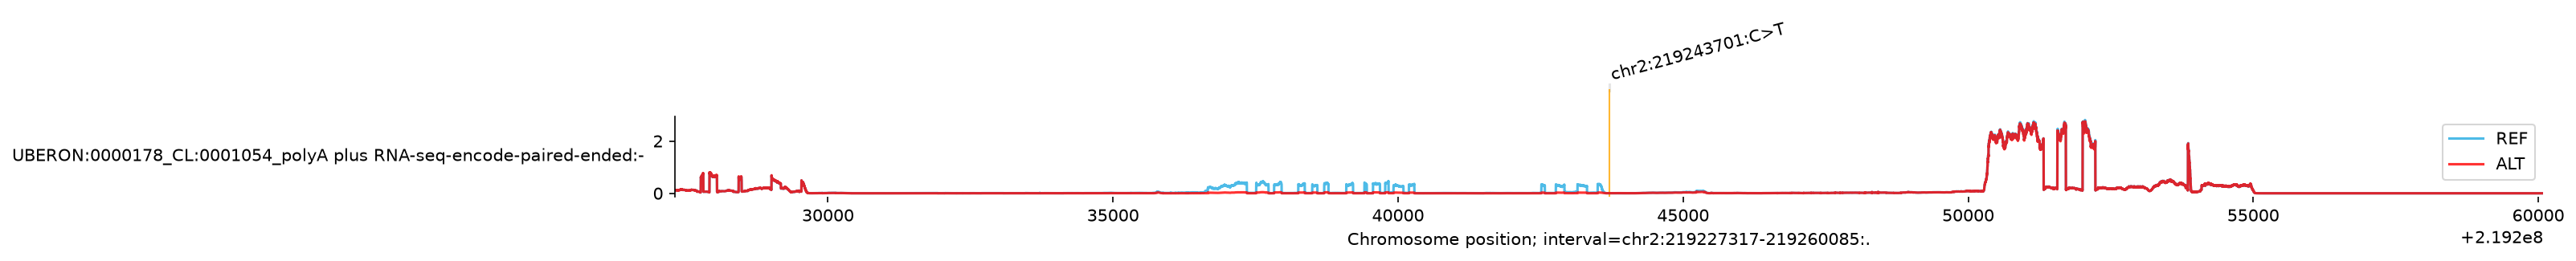

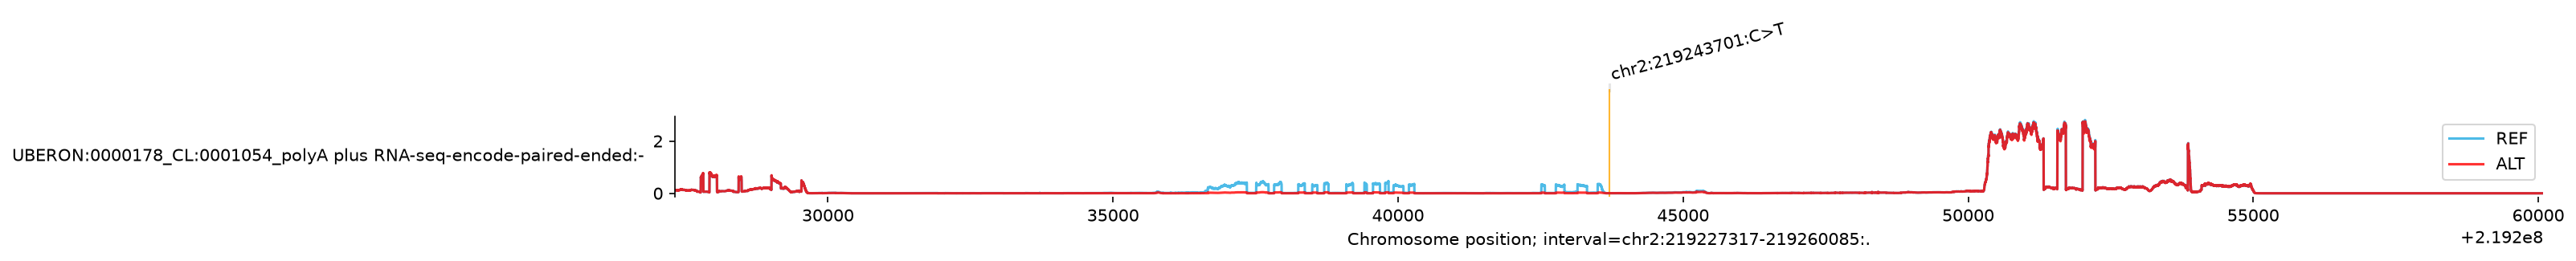

In [7]:

# 1. Choose a condition: CD14-positive monocytes in blood.
condition = 'UBERON:0000178_CL:0001054'

# 2. Select a genomic region: center a 1 Mb interval on the variant.
variant = genome.Variant(
    chromosome='chr2',
    position=219243701,
    reference_bases='C',
    alternate_bases='T',
)
interval = variant.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)

# 3a. Predict REF and ALT RNA-seq tracks across all channels
output = dna_model.predict_variant(
    interval=interval,
    variant=variant,
    requested_outputs=[dna_client.OutputType.RNA_SEQ],
    condition=condition,
)

# 3b. Score the variant effect across genes and filter to GLB1L.
scores = dna_model.score_variant(
    interval=interval,
    variant=variant,
    variant_scorers=[variant_scorers.RECOMMENDED_VARIANT_SCORERS['RNA_SEQ']],
    condition=condition,
)
tidy = variant_scorers.tidy_scores([scores]).query('gene_name == "GLB1L"')

# 4. Plot observed REF versus ALT tracks on the negative strand, where GLB1L lies.
ref_tracks = output.reference.filter_to_observed().rna_seq
alt_tracks = output.alternate.filter_to_observed().rna_seq

plot_components.plot(
    [
        plot_components.OverlaidTracks(
            tdata={
                'REF': ref_tracks.filter_to_negative_strand(),
                'ALT': alt_tracks.filter_to_negative_strand(),
            },
            colors={'REF': '#22AAE1', 'ALT': 'red'},
        )
    ],
    interval=variant.reference_interval.resize(2**15),
    annotations=[plot_components.VariantAnnotation([variant])]
)

In [8]:
tidy

,variant_id,scored_interval,gene_id,gene_name,gene_type,gene_strand,junction_Start,junction_End,output_type,variant_scorer,...,imputation_mode,biosample_curie,biosample_type,biosample_name,Assay title,data_source,genetically_modified,endedness,data_pipeline,raw_score
26,chr2:219243701:C>T,chr2:218719413-219767989:.,ENSG00000163521,GLB1L,protein_coding,-,None,None,RNA_SEQ,"GeneMaskLFCScorer(requested_output=RNA_SEQ, ag...",...,observed,UBERON:0000178_CL:0001054,primary_cell,blood CD14-positive monocyte,polyA plus RNA-seq,encode,False,paired,encode,-2.262954
99,chr2:219243701:C>T,chr2:218719413-219767989:.,ENSG00000163521,GLB1L,protein_coding,-,None,None,RNA_SEQ,"GeneMaskLFCScorer(requested_output=RNA_SEQ, ag...",...,imputed_supported,UBERON:0000178_CL:0001054,primary_cell,blood CD14-positive monocyte,polyA plus RNA-seq,NaN,NaN,single,encode,-1.976817
172,chr2:219243701:C>T,chr2:218719413-219767989:.,ENSG00000163521,GLB1L,protein_coding,-,None,None,RNA_SEQ,"GeneMaskLFCScorer(requested_output=RNA_SEQ, ag...",...,imputed_supported,UBERON:0000178_CL:0001054,primary_cell,blood CD14-positive monocyte,total RNA-seq,NaN,NaN,paired,encode,-2.245536
245,chr2:219243701:C>T,chr2:218719413-219767989:.,ENSG00000163521,GLB1L,protein_coding,-,None,None,RNA_SEQ,"GeneMaskLFCScorer(requested_output=RNA_SEQ, ag...",...,imputed_supported,UBERON:0000178_CL:0001054,primary_cell,blood CD14-positive monocyte,total RNA-seq,NaN,NaN,single,encode,-2.196891
318,chr2:219243701:C>T,chr2:218719413-219767989:.,ENSG00000163521,GLB1L,protein_coding,-,None,None,RNA_SEQ,"GeneMaskLFCScorer(requested_output=RNA_SEQ, ag...",...,observed,UBERON:0000178_CL:0001054,primary_cell,blood CD14-positive monocyte,polyA plus RNA-seq,recount3,False,paired,recount3,-2.422853


## Choosing a condition

Every AlphaGenome 2 prediction is made for one **condition**: the biological context (such as a tissue, cell type, cell line, or your own population of cells) that the model makes predictions for. Choosing the condition is the first step of an analysis.

AlphaGenome 2 supports two ways to specify a condition:

| Mode | Arguments | When to use |
| :-- | :-- | :-- |
| **Reference condition** | `condition='UBERON:0000178_CL:0001054'` | Your tissue, cell type, or cell line is in `supported_conditions` and you want observed-track metadata. Covered in this tutorial. |
| **Expression conditioning** | `cell_conditioning=cells, cell_condition_name='...'` | You have human scRNA-seq raw UMI counts (`AnnData`, up to 256 cells per call via `dna_client.MAX_CONDITIONING_CELLS`). See [Conditioning on your own single-cell data](https://www.alphagenomedocs.com/colabs/v2/conditioning_on_single_cell_data.html). |

Key activities:

1. List the supported reference conditions and search them by name.

2. Check which output types are observed or imputed for a condition.

3. Inspect the observed training tracks for a condition.

### List the supported conditions
`supported_conditions` returns one row per reference condition, with its ontology CURIE (`condition`), a readable `biosample_name`, `biosample_type`, and the imputation mode of each output type:

In [9]:
conditions = dna_model.supported_conditions(dna_client.Organism.HOMO_SAPIENS)

print(f'{len(conditions)} supported human conditions')
conditions.head()

2799 supported human conditions


,condition,biosample_type,biosample_name,atac,cage,dnase,rna_seq,chip_histone,chip_tf,splice_sites,splice_site_usage,splice_junctions,contact_maps,sc_atac,sc_gene_expression,methylation
0,CL:0000047,primary_cell,neural stem cell,imputed_supported,imputed_exploratory,observed,observed,observed,imputed_exploratory,observed,observed,observed,imputed_exploratory,imputed_supported,imputed_supported,imputed_supported
1,CL:0000100,in_vitro_differentiated_cells,motor neuron,observed,imputed_exploratory,imputed_supported,observed,observed,imputed_exploratory,observed,observed,observed,imputed_exploratory,imputed_supported,imputed_supported,imputed_supported
2,CL:0000115,primary_cell,endothelial cell,imputed_supported,imputed_exploratory,observed,observed,imputed_supported,observed,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_supported,imputed_supported,imputed_supported
3,CL:0000134,primary_cell,mesenchymal stem cell,imputed_supported,imputed_exploratory,observed,observed,observed,imputed_exploratory,observed,observed,observed,imputed_exploratory,imputed_supported,imputed_supported,imputed_supported
4,CL:0000136,primary_cell,adipocyte,imputed_supported,imputed_exploratory,observed,imputed_supported,observed,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_exploratory,imputed_supported,imputed_supported,imputed_supported


### Search for a condition by name
Search the `biosample_name` column for the tissue or cell type you are interested in. Here we look for CD14-positive monocytes:

In [10]:
monocytes = conditions[
    conditions['biosample_name'].str.contains('CD14-positive monocyte')
]
monocytes[['condition', 'biosample_name', 'rna_seq', 'atac']]

,condition,biosample_name,rna_seq,atac
442,UBERON:0000178_CL:0001054,blood CD14-positive monocyte,observed,imputed_supported
1451,UBERON:0002048_CL:0001054,lung CD14-positive monocyte,imputed_supported,imputed_supported
1515,UBERON:0002078_CL:0001054,right cardiac atrium CD14-positive monocyte,imputed_supported,imputed_supported
1544,UBERON:0002079_CL:0001054,left cardiac atrium CD14-positive monocyte,imputed_supported,imputed_supported
1571,UBERON:0002080_CL:0001054,heart right ventricle CD14-positive monocyte,imputed_supported,imputed_supported
1604,UBERON:0002084_CL:0001054,heart left ventricle CD14-positive monocyte,imputed_supported,imputed_supported
1636,UBERON:0002094_CL:0001054,interventricular septum CD14-positive monocyte,imputed_supported,imputed_supported
1734,UBERON:0002098_CL:0001054,apex of heart CD14-positive monocyte,imputed_supported,imputed_supported
2028,UBERON:0002185_CL:0001054,bronchus CD14-positive monocyte,imputed_supported,imputed_supported
2114,UBERON:0002351_CL:0001054,sinoatrial node CD14-positive monocyte,imputed_supported,imputed_supported


### Check which outputs are observed

For each output type, `supported_conditions` reports whether predictions for that condition are observed, `imputed_supported`, or `imputed_exploratory`. See [Navigating imputed tracks](https://www.alphagenomedocs.com/user_guides/imputation.html) for what each mode means and pitfalls to keep in mind when using imputed tracks.

Let’s look at which outputs are available for CD14-positive monocytes from blood:

In [11]:
condition = 'UBERON:0000178_CL:0001054'  # CD14-positive monocytes in blood.

conditions.set_index('condition').loc[[condition]].T

condition,UBERON:0000178_CL:0001054
biosample_type,primary_cell
biosample_name,blood CD14-positive monocyte
atac,imputed_supported
cage,imputed_exploratory
dnase,observed
rna_seq,observed
chip_histone,observed
chip_tf,observed
splice_sites,observed
splice_site_usage,observed


### Inspect the observed tracks

`observed_metadata` lists every track the model was trained on. Filtering it to our condition shows the experiments behind the `observed` output types:

In [12]:
pd.set_option('display.max_colwidth', None)
observed = dna_model.observed_metadata(
    dna_client.Organism.HOMO_SAPIENS
).concatenate()

observed[observed['biosample_curie'] == condition][
    ['output_type', 'Assay title', 'strand', 'name']
]

,output_type,Assay title,strand,name
190,OutputType.DNASE,DNase-seq,.,UBERON:0000178_CL:0001054_DNase-seq-encode-paired-ended
191,OutputType.DNASE,DNase-seq,.,UBERON:0000178_CL:0001054_DNase-seq-encode-single-ended
450,OutputType.RNA_SEQ,polyA plus RNA-seq,+,UBERON:0000178_CL:0001054_polyA plus RNA-seq-encode-paired-ended
451,OutputType.RNA_SEQ,polyA plus RNA-seq,-,UBERON:0000178_CL:0001054_polyA plus RNA-seq-encode-paired-ended
452,OutputType.RNA_SEQ,polyA plus RNA-seq,.,UBERON:0000178_CL:0001054_polyA plus RNA-seq-encode-paired-ended
453,OutputType.RNA_SEQ,polyA plus RNA-seq,.,UBERON:0000178_CL:0001054_polyA plus RNA-seq-gtex-paired-ended
599,OutputType.CHIP_HISTONE,Histone ChIP-seq,.,UBERON:0000178_CL:0001054_Histone ChIP-seq-encode-H2AFZ-single-ended
600,OutputType.CHIP_HISTONE,Histone ChIP-seq,.,UBERON:0000178_CL:0001054_Histone ChIP-seq-encode-H3K27ac-single-ended
601,OutputType.CHIP_HISTONE,Histone ChIP-seq,.,UBERON:0000178_CL:0001054_Histone ChIP-seq-encode-H3K27me3-single-ended
602,OutputType.CHIP_HISTONE,Histone ChIP-seq,.,UBERON:0000178_CL:0001054_Histone ChIP-seq-encode-H3K36me3-single-ended


The same metadata summarizes training coverage across all conditions, for example the number of observed tracks per output type in human and mouse (see [Model output metadata](https://www.alphagenomedocs.com/exploring_model_metadata.html)):

In [13]:
human_tracks = (
    observed.groupby('output_type').size().rename('# Human tracks')
)
mouse_tracks = (
    dna_model.observed_metadata(dna_client.Organism.MUS_MUSCULUS)
    .concatenate()
    .groupby('output_type')
    .size()
    .rename('# Mouse tracks')
)

pd.concat([human_tracks, mouse_tracks], axis=1).astype(pd.Int64Dtype())

,# Human tracks,# Mouse tracks
output_type,,
OutputType.ATAC,179,27
OutputType.CAGE,550,188
OutputType.DNASE,385,86
OutputType.RNA_SEQ,738,206
OutputType.CHIP_HISTONE,1183,190
OutputType.CHIP_TF,1709,145
OutputType.SPLICE_SITES,1135,295
OutputType.SPLICE_SITE_USAGE,560,126
OutputType.SPLICE_JUNCTIONS,280,63


### Using the condition
Pass the ontology CURIE string directly as `condition=` or construct a `model_condition.ModelCondition` from component CURIEs:

In [14]:
model_condition.from_curies(['UBERON:0000178', 'CL:0001054'])

ModelCondition(clo=None, uberon=OntologyTerm(type=<OntologyType.UBERON: 2>, id=178), cl=OntologyTerm(type=<OntologyType.CL: 3>, id=1054), efo=None, ntr=None)

`predict_interval`, `predict_variant`, and `score_variant` accept one condition per call (and multiple requested output types concurrently); to compare several conditions, loop over them or pass matching lists to `predict_intervals`, `predict_variants`, or `score_variants`.

## Selecting a genomic region

AlphaGenome 2 makes predictions for a DNA sequence of fixed length, centered on the region you care about. After choosing a condition, the second step of an analysis is to describe that input: a `genome.Interval` on the reference genome, an interval around a specific `genome.Variant`, or a custom DNA string.

Here we set up the genomic region around the GLB1L gene and a nearby variant, chr2:219243701:C>T.

Key activities:

1. Create a `genome.Interval` and resize it to the recommended 1 Mb context length (`dna_client.SEQUENCE_LENGTH_1MB`).

2. Look up the interval of a gene from GENCODE annotations.

3. Define a genome.Variant and center the 1 Mb interval on the variant.

4. Prepare a custom DNA sequence string for predict_sequence.

### Supported sequence lengths
AlphaGenome 2 accepts four input sequence lengths: 
- 16 kb (16,384 bp, `dna_client.SEQUENCE_LENGTH_16KB`)

- 131,072 bp (`dna_client.SEQUENCE_LENGTH_100KB`)

- 524,288 bp (`dna_client.SEQUENCE_LENGTH_500KB`)

- 1 Mb (`1,048,576 bp, dna_client.SEQUENCE_LENGTH_1MB`):

> Use a 1Mb interval whenever possible for best accuracy, and center variants inside the interval (`variant.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)`) so the model sees sequence context on both sides.

In [15]:
list(dna_client.SUPPORTED_SEQUENCE_LENGTHS.keys())

['SEQUENCE_LENGTH_16KB',
 'SEQUENCE_LENGTH_100KB',
 'SEQUENCE_LENGTH_500KB',
 'SEQUENCE_LENGTH_1MB']

### Define an interval

A `genome.Interval` is a genomic region with a 0-based start and an exclusive end position:

In [16]:
interval = genome.Interval(chromosome='chr2', start=219_200_000, end=219_300_000)

print(interval)
print(f'Width: {interval.width:,} bp')

chr2:219200000-219300000:.
Width: 100,000 bp


`resize` expands (or shrinks) the interval around its center to the requested width, adding reference genome sequences on both sides. Use `dna_client.SEQUENCE_LENGTH_1MB` for full context:

In [17]:
interval_1mb = interval.resize(dna_client.SEQUENCE_LENGTH_1MB)

print(interval_1mb)
print(f'Width: {interval_1mb.width:,} bp')

chr2:218725712-219774288:.
Width: 1,048,576 bp


### Start from a gene

Often, you will want to start from a gene rather than from coordinates. GENCODE annotations (in GTF format) give the location of every gene:

In [18]:
# GENCODE v46 gene annotations for the hg38 human genome assembly.
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)

In [19]:
gene_interval = gene_annotation.get_gene_interval(gtf, gene_symbol='GLB1L')
gene_interval

Interval(chromosome='chr2', start=219236597, end=219245478, strand='-', name='GLB1L')

`get_gene_interval` also records whether the gene lies on the `+` or `-` strand. Remember to resize the interval to `dna_client.SEQUENCE_LENGTH_1MB` before making predictions:

In [20]:
gene_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)

Interval(chromosome='chr2', start=218716749, end=219765325, strand='-', name='GLB1L')

### Start from a variant

A `genome.Variant` is specified by its chromosome, 1-based position (as in VCF files), and reference and alternate alleles:

In [21]:
variant = genome.Variant(
    chromosome='chr2',
    position=219243701,
    reference_bases='C',
    alternate_bases='T',
)
print(variant)

chr2:219243701:C>T


`reference_interval` covers the reference allele. Resizing `reference_interval` to `dna_client.SEQUENCE_LENGTH_1MB` centers the 1 Mb prediction window on the variant, which is recommended for variant effect predictions and scoring:

In [22]:
interval = variant.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)
interval

Interval(chromosome='chr2', start=218719413, end=219767989, strand='.', name='')

The centered 1 Mb window around the variant contains the whole GLB1L gene:

In [23]:
interval.contains(gene_interval)

True

### Define a DNA sequence

For `dna_model.predict_sequence`, provide a string of `A`, `C`, `G`, `T`, and `N` whose length matches one of `dna_client.SUPPORTED_SEQUENCE_LENGTHS`. Pad shorter motifs or synthetic constructs with `N`, centering your sequence of interest (16 kb via `dna_client.SEQUENCE_LENGTH_16KB` or 1 Mb via `dna_client.SEQUENCE_LENGTH_1MB`). Note that extensively `N`-padded sequences have not been benchmarked and may affect prediction performance.

In [24]:
sequence = 'GATTACA'.center(dna_client.SEQUENCE_LENGTH_16KB, 'N')
print(f'Sequence length: {len(sequence):,} bp')

Sequence length: 16,384 bp


## Predicting tracks for an interval or sequence
This tutorial predicts tracks for a genomic interval with predict_interval and for a custom DNA string with `predict_sequence`. We first predict across CD19 in blood B cells (`UBERON:0000178_CL:0000236`), where bulk and single-cell RNA-seq and ATAC-seq tracks are directly observed; we then predict DNase-seq and histone ChIP-seq from a padded DNA string.

Key activities:

1. Choose a condition and output types, and define a `genome.Interval`

2. Make track predictions using `predict_interval` and `predict_sequence`

3. Visualize bulk and single-cell track predictions

We first load GENDOCE gene adn transcript annotations in GTF format:

In [25]:
# Get the MANE transcript (one curated transcript per locus)
gtf_transcripts = gene_annotation.filter_protein_coding(gtf)
gtf_transcripts_mane = gene_annotation.filter_to_mane_select_transcript(gtf_transcripts)

# Set up transcript extractors using the information in the GTF file.
transcript_extractor_mane = transcript_utils.TranscriptExtractor(
    gtf_transcripts_mane
)

### Predict interval (bulk)
`predict_interval` predicts tracks for a reference genome `genome.Interval`. It takes a condition, the interval, and a list of requested output types as input.

#### Set condition and output type

Use a reference condition CURIE:

In [29]:
# Set biosample.
target_condition = 'UBERON:0000178_CL:0000236' # Blood B cells

# Set output types.
target_output = [
    dna_client.OutputType.RNA_SEQ,
    dna_client.OutputType.ATAC,
]

> **Tip:** For expression conditioning (`cell_conditioning=`) alongside `cell_condition_name=` with your own human scRNA-seq counts, request `dna_client.OutputType.SC_GENE_EXPRESSION_DENOISED` for denoised single-cell gene expression as target output.

#### Define interval

Define a genomic interval by creating a `genome.Interval` object. Here we fetch teh gene interval for *CD19* and resize it to 1 Mb:

In [ ]:
# Fetch the location of the gene from the GTF file.
gene_interval = gene_annotation.get_gene_interval(gtf, gene_symbol='CD19')

# Expand (resize) the interval to a model-compatible size.
interval = gene_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)

#### Predict Interval

Make predictions using `predict_interval`:

In [30]:
output = dna_model.predict_interval(
    interval=interval,
    requested_outputs=target_output,
    condition=target_condition,
)

Most requested output types return a `TrackData` object of shape `(num_positions, num_tracks)` (`SC_GENE_EXPRESSION` returns a `GeneExpressionData` object of shape `(num_genes, num_tracks)`, `SLICE_JUNCTIONS` returns a `JunctionData` object, and `CELL_EMBEDDINGS` returns a `numpy.ndarray`).

In [31]:
# Shape of RNA output.
output.rna_seq.values.shape

(1048576, 12)

A condition returns multiple tracks per output type across channels and strands. Inspect `metadata["imputation_mode"]` to see which tracks were directly `observed` in training and which are imputed.

In [32]:
output.rna_seq.metadata

,name,strand,biosample_curie,imputation_mode,biosample_type,biosample_name,Assay title,data_source,genetically_modified,endedness,data_pipeline
0,UBERON:0000178_CL:0000236_polyA plus RNA-seq-encode-paired-ended,+,UBERON:0000178_CL:0000236,observed,primary_cell,blood B cell,polyA plus RNA-seq,encode,False,paired,encode
1,UBERON:0000178_CL:0000236_polyA plus RNA-seq-encode-single-ended,+,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,polyA plus RNA-seq,NaN,NaN,single,encode
2,UBERON:0000178_CL:0000236_total RNA-seq-encode-paired-ended,+,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,total RNA-seq,NaN,NaN,paired,encode
3,UBERON:0000178_CL:0000236_total RNA-seq-encode-single-ended,+,UBERON:0000178_CL:0000236,observed,primary_cell,blood B cell,total RNA-seq,encode,False,single,encode
4,UBERON:0000178_CL:0000236_polyA plus RNA-seq-encode-paired-ended,-,UBERON:0000178_CL:0000236,observed,primary_cell,blood B cell,polyA plus RNA-seq,encode,False,paired,encode
5,UBERON:0000178_CL:0000236_polyA plus RNA-seq-encode-single-ended,-,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,polyA plus RNA-seq,NaN,NaN,single,encode
6,UBERON:0000178_CL:0000236_total RNA-seq-encode-paired-ended,-,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,total RNA-seq,NaN,NaN,paired,encode
7,UBERON:0000178_CL:0000236_total RNA-seq-encode-single-ended,-,UBERON:0000178_CL:0000236,observed,primary_cell,blood B cell,total RNA-seq,encode,False,single,encode
8,UBERON:0000178_CL:0000236_polyA plus RNA-seq-encode-paired-ended,.,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,polyA plus RNA-seq,NaN,NaN,paired,encode
9,UBERON:0000178_CL:0000236_polyA plus RNA-seq-encode-single-ended,.,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,polyA plus RNA-seq,NaN,NaN,single,encode


#### Subset tracks

Prediction containers can be filtered using convenience methods (such as `.filter_to_protein_coding()`, `.filter_to_observed()`, and `.filter_to_positive_strand()`) or by indexing with boolean masks over `.metadata` and `.gene_metadata`:

The metadata shows the `imputation_mode`, assay protocol (`polyA plus RNA-seq` and `total RNA-seq`), and DNA strand of each track:

In [33]:
# Subset RNA-seq to paired, observed positive-strand tracks
mask_rna = (
    (output.rna_seq.metadata.endedness == 'paired')
    & (output.rna_seq.metadata['imputation_mode'] == 'observed')
    & (output.rna_seq.metadata.strand == '+')
).values
rna_subset = output.rna_seq[:, mask_rna]

# Subset ATAC to observed tracks
mask_atac = (output.atac.metadata['imputation_mode'] == 'observed').values
atac_subset = output.atac[:, mask_atac]

#### Visualize

Plot the predicted RNA-seq and ATAC-seq tracks alongside the MANE Select transcripts in the 1 Mb region, zooming in around *CD19*.

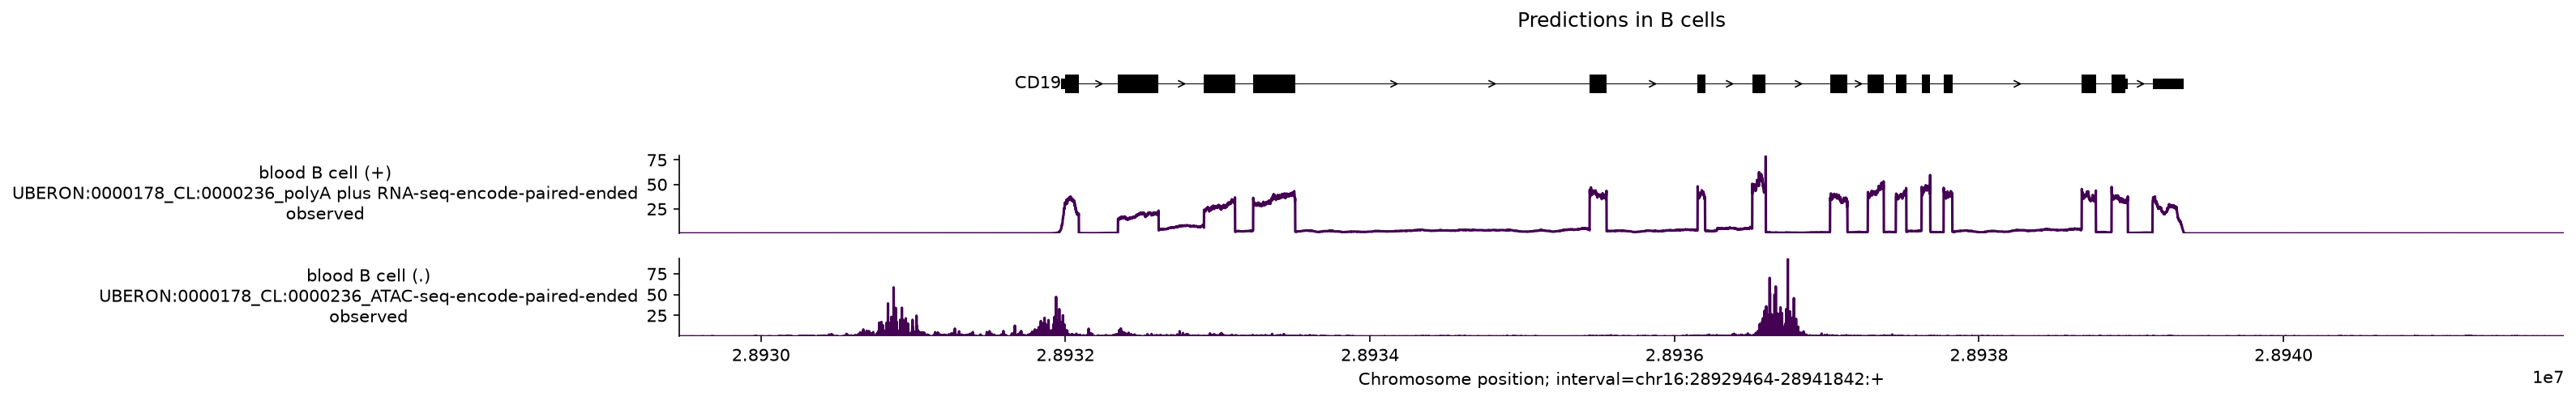

In [34]:
# Extract transcripts
transcripts = transcript_extractor_mane.extract(interval)

# Plot
plot_components.plot(
    components=[
        # Add transcripts to plot
        plot_components.TranscriptAnnotation(transcripts),
        # Add RNA output
        plot_components.Tracks(
            rna_subset,
            ylabel_template=(
                '{biosample_name} ({strand})\n{name}\n{imputation_mode}'
            ),
        ),
        # Add ATAC output
        plot_components.Tracks(
            atac_subset,
            ylabel_template=(
                '{biosample_name} ({strand})\n{name}\n{imputation_mode}'
            ),
        ),
    ],
    interval=gene_interval.resize(gene_interval.width + 5000),
    title='Predictions in B cells',
)

plt.show()

### Predict interval (pseudobulk)

For pseudobulk scRNA-seq (`SC_GENE_EXPRESSION`), the model returns one predicted expression value (in counts per million) per annotated gene in the interval rather than a base-pair coverage track. 

#### Predict interval

Make single-cell predictions using `predict_interval`:

In [35]:
output_sc = dna_model.predict_interval(
    interval=interval, # same interval
    requested_outputs=[
        dna_client.OutputType.SC_GENE_EXPRESSION,
        dna_client.OutputType.SC_ATAC
    ],
    condition=target_condition # same condition
)

The scATAC-seq output returns a `TrackData` object whose track metadata can be accessed as follows:

In [ ]:
# View track metadata for scATAC-seq
output_sc.sc_atac.metadata

,name,strand,biosample_curie,imputation_mode,biosample_type,biosample_name,Assay title,suspension_type,data_pipeline
0,UBERON:0000178_CL:0000236_EasySci-ATAC-easy_sci-nuclear,.,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,EasySci-ATAC,nuclear,easy_sci
1,UBERON:0000178_CL:0000236_SHARE-seq-cellranger-nuclear,.,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,SHARE-seq,nuclear,cellranger
2,UBERON:0000178_CL:0000236_scATAC-seq 10X-bowtie2-nuclear,.,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,scATAC-seq 10X,nuclear,encode
3,UBERON:0000178_CL:0000236_scATAC-seq 10X-cellranger-nuclear,.,UBERON:0000178_CL:0000236,observed,primary_cell,blood B cell,scATAC-seq 10X,nuclear,cellranger
4,UBERON:0000178_CL:0000236_sciATAC-seq-bowtie2-nuclear,.,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,sciATAC-seq,nuclear,encode


The scRNA-seq output predictes gene expression per gene in a `GeneExpressionData` object with both `.track_metadata` and `.gene_metadata`:

In [37]:
# View track metadata for scRNA-seq
output_sc.sc_gene_expression.track_metadata

,name,strand,biosample_curie,imputation_mode,biosample_type,biosample_name,Assay title,suspension_type,data_pipeline,cellxgene_dataset_id,paper_doi
0,UBERON:0000178_CL:0000236_EasySci-easy_sci-nuclear,+,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,EasySci,nuclear,easy_sci,NaN,NaN
1,UBERON:0000178_CL:0000236_SHARE-seq-share_seq-nuclear,+,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,SHARE-seq,nuclear,share_seq,NaN,NaN
2,UBERON:0000178_CL:0000236_SPLIT-seq-star_solo-nuclear,+,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,SPLIT-seq,nuclear,encode,NaN,NaN
3,UBERON:0000178_CL:0000236_scRNA-seq 10X 3-cellranger-cell,+,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,scRNA-seq 10X 3,cell,cellranger,NaN,NaN
4,UBERON:0000178_CL:0000236_scRNA-seq 10X 3-cellranger-nuclear,+,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,scRNA-seq 10X 3,nuclear,cellranger,NaN,NaN
5,UBERON:0000178_CL:0000236_scRNA-seq 10X 3-star_solo-nuclear,+,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,scRNA-seq 10X 3,nuclear,encode,NaN,NaN
6,UBERON:0000178_CL:0000236_scRNA-seq 10X 5-cellranger-cell,+,UBERON:0000178_CL:0000236,observed,primary_cell,blood B cell,scRNA-seq 10X 5,cell,cellranger,3a8a77a6-f069-479c-a2c1-252feafd0106,10.1016/j.cell.2025.02.017
7,UBERON:0000178_CL:0000236_EasySci-easy_sci-nuclear,-,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,EasySci,nuclear,easy_sci,NaN,NaN
8,UBERON:0000178_CL:0000236_SHARE-seq-share_seq-nuclear,-,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,SHARE-seq,nuclear,share_seq,NaN,NaN
9,UBERON:0000178_CL:0000236_SPLIT-seq-star_solo-nuclear,-,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,SPLIT-seq,nuclear,encode,NaN,NaN


In [38]:
# View gene metadata for sc gene expression
output_sc.sc_gene_expression.gene_metadata

,gene_id,Chromosome,Start,End,strand,gene_name,gene_type
0,ENSG00000103472.10,chr16,29074975,29116718,+,RRN3P2,lncRNA
1,ENSG00000168488.19,chr16,28822998,28837237,+,ATXN2L,protein_coding
2,ENSG00000169682.18,chr16,28974220,28984548,+,SPNS1,protein_coding
3,ENSG00000176046.9,chr16,28532707,28539008,-,NUPR1,protein_coding
4,ENSG00000176476.9,chr16,28553914,28591790,+,SGF29,protein_coding
...,...,...,...,...,...,...,...
76,ENSG00000289756.1,chr16,28620062,28623482,-,ENSG00000289756,transcribed_unprocessed_pseudogene
77,ENSG00000290677.1,chr16,29103656,29108108,-,ENSG00000290677,lncRNA
78,ENSG00000290680.1,chr16,29350745,29370272,+,ENSG00000290680,lncRNA
79,ENSG00000291188.1,chr16,29114716,29217860,+,ENSG00000291188,lncRNA


#### Subset tracks

Prediction containers can be filtered using convenience methods (such as `.filter_to_protein_coding()`, `.filter_to_observed()`, and `.filter_to_positive_strand()`) or by indexing with boolean masks over `.metadata` and `.gene_metadata`:

In [ ]:
# Subset single-cell gene expression to positive-strand protein-coding genes and observed + tracks.
rna_subset = (
    output_sc.sc_gene_expression.filter_to_protein_coding()
    .filter_to_observed()
    .filter_to_positive_strand()
)
rna_subset = rna_subset[rna_subset.gene_metadata['strand'] == '+']

# Subset scATAC to observed tracks
mask_atac = (
    output_sc.sc_atac.metadata['imputation_mode'] == 'observed'
).values
atac_subset = output_sc.sc_atac[:, mask_atac]

#### Visualize

We filter to protein-coding genes and observed positive-strand (`+`) tracks, since *CD19* is transcribed from the positive strand, and plot single-interval `SC_GENE_EXPRESSION` outputs with `plot_components.GeneExpression` (use plot_components.OverlaidGeneExpression` for variant REF/ALT comparisons):

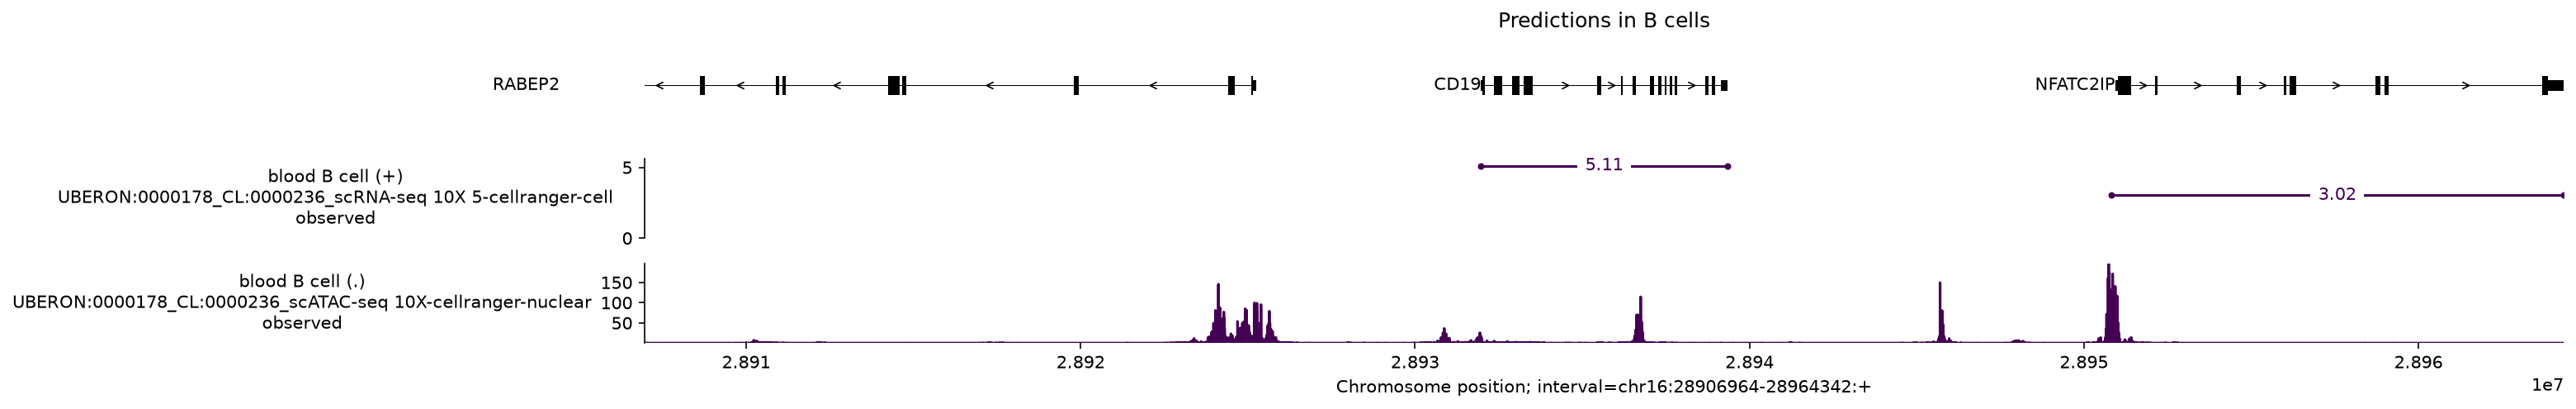

In [40]:
# Extract transcripts
transcripts = transcript_extractor_mane.extract(interval)

# Plot
plot_components.plot(
    components=[
        # Add transcripts to plot
        plot_components.TranscriptAnnotation(transcripts),
        # Add single cell RNA output
        plot_components.GeneExpression(
            rna_subset,
            log_scale=True,
            ylabel_template=(
                '{biosample_name} ({strand})\n{name}\n{imputation_mode}'
            )
        ),
        # Add single cell ATAC output.
        plot_components.Tracks(
            atac_subset,
            ylabel_template=(
                '{biosample_name} ({strand})\n{name}\n{imputation_mode}'
            ),
        ),
    ],
    interval=gene_interval.resize(gene_interval.width + 50000),
    title='Predictions in B cells',
)

plt.show()

### Predict a sequence

Instead of an interval on the reference genome, you can predict for any DNA sequence of a supported length with `predict_sequence`. Pad shorter sequences with `N` to reach one of the supported sequence lengths. Sequence predictions are useful for synthetic or edited sequences, though gene-level `SC_GENE_EXPRESSION` requires reference genome coordinates (`predict_interval`, `predict_variant`, or `score_variant`).

Here we predict DNase-seq tracks in lung tissue (`UBERON:0002048`) for a DNA sequence padded to 16 kb (`dna_client.SEQUENCE_LENGTH_16KB`, 16,384 bp; for endogenous genomic loci, prefer 1 Mb via `dna_client.SEQUENCE_LENGTH_1MB`):

In [43]:
output = dna_model.predict_sequence(
    sequence='GATTACA'.center(
        dna_client.SEQUENCE_LENGTH_16KB, 'N'
    ), # Pad to valid sequence length
    requested_outputs=[dna_client.OutputType.DNASE],
    condition='UBERON:0002048',  # Lung
)

`output.dnase` is a `TrackData` object with `.values` of shape `(sequence_length, num_tracks)` and track descriptions in `.metadata`

In [44]:
dnase = output.dnase
type(dnase)

alphagenome.data.track_data.TrackData

Let's look at the track metadata:

In [45]:
dnase.metadata

,name,strand,biosample_curie,imputation_mode,biosample_type,biosample_name,Assay title,data_source,genetically_modified,endedness,data_pipeline
0,UBERON:0002048_DNase-seq-encode-paired-ended,.,UBERON:0002048,observed,tissue,lung,DNase-seq,encode,False,paired,encode
1,UBERON:0002048_DNase-seq-encode-single-ended,.,UBERON:0002048,observed,tissue,lung,DNase-seq,encode,False,single,encode


Here lung DNase-seq has 2 channels (paired-end and single-end), so `.metadata` has 2 rows. Track metadata is especially useful for stranded assays (such as CAGE and RNA-seq) and for checking whether each track is observed or imputed.

We can index tracks with a boolean mask on `metadata['imputation_mode']` to keep only directly measured (`observed`) tracks:

In [46]:
observed_mask = (dnase.metadata.imputation_mode == 'observed').values
subset_dnase = dnase[:, observed_mask]
subset_dnase.metadata

,name,strand,biosample_curie,imputation_mode,biosample_type,biosample_name,Assay title,data_source,genetically_modified,endedness,data_pipeline
0,UBERON:0002048_DNase-seq-encode-paired-ended,.,UBERON:0002048,observed,tissue,lung,DNase-seq,encode,False,paired,encode
1,UBERON:0002048_DNase-seq-encode-single-ended,.,UBERON:0002048,observed,tissue,lung,DNase-seq,encode,False,single,encode


Histone ChIP-seq (`CHIP_HISTONE`) and TF ChIP-seq (`CHIP_TF`) are predicted at 128bp resolution rather than 1 bp:

In [49]:
output = dna_model.predict_sequence(
    sequence='GATTACA'.center(
        dna_client.SEQUENCE_LENGTH_16KB, 'N'
    ),  # Pad to valid sequence length.
    requested_outputs=[
        dna_client.OutputType.CHIP_TF,
    ],
    condition='UBERON:0000955',  # Brain.
)

print(f'ChIP predictions shape: {output.chip_tf.values.shape}')
print(
    'ChIP predictions resolution:'
    f' {int(dna_client.SEQUENCE_LENGTH_16KB / output.chip_tf.values.shape[0])} bp'
)

ChIP predictions shape: (128, 911)
ChIP predictions resolution: 128 bp
